In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/processed/cleaned_encoded.csv")

In [3]:
df.shape

(1470, 45)

In [5]:
print(df.columns.tolist())

['Age', 'Attrition', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'BusinessTravel_Travel_Frequently', 'BusinessTravel_Travel_Rarely', 'Department_Research & Development', 'Department_Sales', 'EducationField_Life Sciences', 'EducationField_Marketing', 'EducationField_Medical', 'EducationField_Other', 'EducationField_Technical Degree', 'Gender_Male', 'JobRole_Human Resources', 'JobRole_Laboratory Technician', 'JobRole_Manager', 'JobRole_Manufacturing Director', 'JobRole_Research Director', 'JobRole_Research Scientist', 'JobRole_Sales Executive', 'JobRole_Sales Representative', 'MaritalStatus_Married', 'M

In [6]:
X = df.drop(columns=["Attrition"])
y = df["Attrition"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (1470, 44)
Target shape: (1470,)

Target distribution:
Attrition
0    1233
1     237
Name: count, dtype: int64


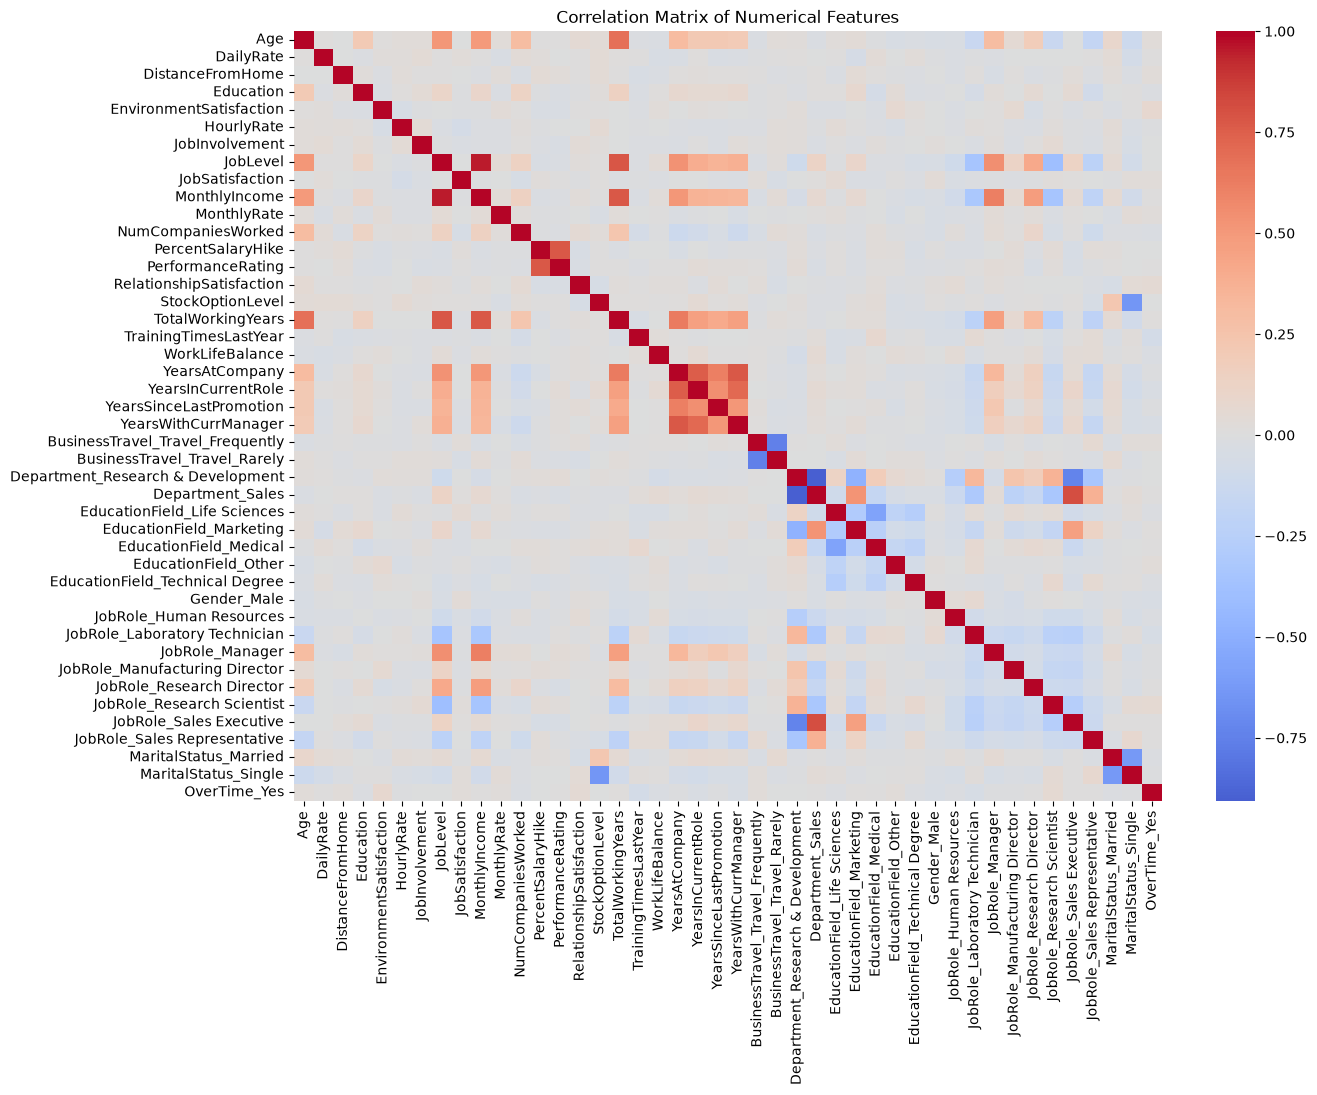

In [7]:
numeric_cols = X.select_dtypes(include="number").columns

corr_matrix = X[numeric_cols].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0)
plt.title("Correlation Matrix of Numerical Features")
plt.show()

In [8]:
corr_pairs = (
    corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )
    .stack()
    .sort_values(ascending=False)
)

print(corr_pairs.head(15))

JobLevel            MonthlyIncome              0.950300
Department_Sales    JobRole_Sales Executive    0.808869
JobLevel            TotalWorkingYears          0.782208
PercentSalaryHike   PerformanceRating          0.773550
MonthlyIncome       TotalWorkingYears          0.772893
YearsAtCompany      YearsWithCurrManager       0.769212
                    YearsInCurrentRole         0.758754
YearsInCurrentRole  YearsWithCurrManager       0.714365
Age                 TotalWorkingYears          0.680381
TotalWorkingYears   YearsAtCompany             0.628133
MonthlyIncome       JobRole_Manager            0.619573
YearsAtCompany      YearsSinceLastPromotion    0.618409
JobLevel            JobRole_Manager            0.552744
YearsInCurrentRole  YearsSinceLastPromotion    0.548056
JobLevel            YearsAtCompany             0.534739
dtype: float64


In [9]:
X = X.drop(columns=["MonthlyIncome"])

print("Features shape after feature selection:", X.shape)
print("MonthlyIncome present:", "MonthlyIncome" in X.columns)

Features shape after feature selection: (1470, 43)
MonthlyIncome present: False


In [10]:
print((X["TotalWorkingYears"] - X["YearsAtCompany"]).min())

0


In [11]:
X["PreviousCompanyExperience"] = (
    X["TotalWorkingYears"] - X["YearsAtCompany"]
)

print(X[[
    "TotalWorkingYears",
    "YearsAtCompany",
    "PreviousCompanyExperience"
]].head())

   TotalWorkingYears  YearsAtCompany  PreviousCompanyExperience
0                  8               6                          2
1                 10              10                          0
2                  7               0                          7
3                  8               8                          0
4                  6               2                          4


In [12]:
X["PreviousCompanyExperience"] = (
    X["TotalWorkingYears"] - X["YearsAtCompany"]
)

In [13]:
print((X["TotalWorkingYears"] == 0).sum())

11


In [14]:
X["CompanyTenureRatio"] = np.where(
    X["TotalWorkingYears"] > 0,
    X["YearsAtCompany"] / X["TotalWorkingYears"],
    0
)



In [15]:
# ==========================================
# ADDITIONAL FEATURE ENGINEERING
# ==========================================

# 1. Role Tenure Ratio
# How much of the employee's company tenure
# has been spent in their current role?

X["RoleTenureRatio"] = np.where(
    X["YearsAtCompany"] > 0,
    X["YearsInCurrentRole"] / X["YearsAtCompany"],
    0
)


# 2. Promotion Gap Ratio
# How much of the employee's company tenure
# has passed since their last promotion?

X["PromotionGapRatio"] = np.where(
    X["YearsAtCompany"] > 0,
    X["YearsSinceLastPromotion"] / X["YearsAtCompany"],
    0
)


# 3. Manager Tenure Ratio
# How much of the employee's company tenure
# has been spent with their current manager?

X["ManagerTenureRatio"] = np.where(
    X["YearsAtCompany"] > 0,
    X["YearsWithCurrManager"] / X["YearsAtCompany"],
    0
)


# 4. Overtime Tenure
# Combines overtime status with years at the company.
# OverTime_Yes = 1 if employee works overtime, otherwise 0.

X["OvertimeTenure"] = (
    X["OverTime_Yes"] * X["YearsAtCompany"]
)


# 5. Work-Life Satisfaction
# Combines WorkLifeBalance and JobSatisfaction
# into one overall measure.

X["WorkLifeSatisfaction"] = (
    X["WorkLifeBalance"] * X["JobSatisfaction"]
)


# 6. Career Progression Score
# Combines current role experience and promotion history.
# Higher values indicate more career progression.

X["CareerProgressionScore"] = (
    X["YearsInCurrentRole"] +
    X["YearsSinceLastPromotion"] +
    X["YearsWithCurrManager"]
)


# Check the newly created features
print("New features created:")
print([
    "RoleTenureRatio",
    "PromotionGapRatio",
    "ManagerTenureRatio",
    "OvertimeTenure",
    "WorkLifeSatisfaction",
    "CareerProgressionScore"
])

print("\nNew X shape:", X.shape)

New features created:
['RoleTenureRatio', 'PromotionGapRatio', 'ManagerTenureRatio', 'OvertimeTenure', 'WorkLifeSatisfaction', 'CareerProgressionScore']

New X shape: (1470, 51)


In [16]:
print("Number of features:", X.shape[1])
print("\nFeatures with only one unique value:")
print(X.nunique()[X.nunique() <= 1])

Number of features: 51

Features with only one unique value:
Series([], dtype: int64)


In [17]:
final_df = X.copy()
final_df["Attrition"] = y

print("Final dataset shape:", final_df.shape)
print("Missing values:", final_df.isnull().sum().sum())
print("\nTarget distribution:")
print(final_df["Attrition"].value_counts())

Final dataset shape: (1470, 52)
Missing values: 0

Target distribution:
Attrition
0    1233
1     237
Name: count, dtype: int64


In [18]:
final_df.to_csv(
    "../data/processed/final_dataset.csv",
    index=False
)

print("Final dataset saved successfully.")

Final dataset saved successfully.


In [19]:
check_df = pd.read_csv("../data/processed/final_dataset.csv")

print("Loaded shape:", check_df.shape)

Loaded shape: (1470, 52)


In [20]:
final_df.to_csv(
    "../data/processed/final_dataset.csv",
    index=False
)

print("Final dataset saved successfully.")

Final dataset saved successfully.
